In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="whitegrid")

log_dir = "logs/"
feat_file = max(glob.glob(f"{log_dir}latency_features_*.csv"), key=os.path.getctime)
ml_file = max(glob.glob(f"{log_dir}latency_ml_*.csv"), key=os.path.getctime)
fb_file = max(glob.glob(f"{log_dir}latency_feedback_*.csv"), key=os.path.getctime)

df_feat = pd.read_csv(feat_file)
df_ml = pd.read_csv(ml_file)
df_fb = pd.read_csv(fb_file)

print(f"Loaded Features: {feat_file}")
print(f"Loaded ML: {ml_file}")
print(f"Loaded Feedback: {fb_file}")

Loaded Features: logs\latency_features_20261026_143541.csv
Loaded ML: logs\latency_ml_20261026_143720.csv
Loaded Feedback: logs\latency_feedback_20261026_143543.csv


In [25]:
# PyGame redraws at 20Hz and logs duplicate timestamps if no new prediction arrived.
# We keep only the 'first' instance a prediction hits the screen.
df_fb_unique = df_fb.drop_duplicates(subset=['Timestamp'], keep='first')

# Inner join to only analyze frames that made it all the way to the screen
df = df_feat.merge(df_ml, on="Timestamp")
df = df.merge(df_fb_unique, on="Timestamp")

# Convert LSL Timestamp to relative seconds from the start of the experiment
df['Time_s'] = df['Timestamp'] - df['Timestamp'].iloc[0]

components = [
    'Acquisition_ms', 
    'Preprocessing_ms', 
    'Feature_ms', 
    'Latency_ms',          # ML inference latency
    'Feedback_Update_ms', 
    'Total_End_to_End_ms'
]

df.head()

,Timestamp,Acquisition_ms,Preprocessing_ms,Feature_ms,Latency_ms,Feedback_Update_ms,Total_End_to_End_ms,Time_s
0,72988.661889,15.7358,0.0263,1.9366,1.0397,0.4016,28.1583,0.000000
1,72988.754757,16.6613,0.0634,1.4355,0.6775,0.4439,36.7785,0.092868
2,72988.864032,16.3586,0.0735,2.1287,0.8809,0.4562,28.0546,0.202142
3,72988.941152,15.8553,0.0724,1.8545,0.8452,0.5239,53.0964,0.279263
4,72989.034797,16.7550,0.0633,1.4443,0.8237,0.4299,61.2343,0.372908


In [26]:
print("--- Basic Descriptive Statistics ---")
display(df[components].describe().round(2))

print("\n--- Tail Latency (95th and 99th Percentile) ---")
display(df[components].quantile([0.95, 0.99]).round(2))

print("\n--- Component Breakdown (%) ---")
mean_latencies = df[components].mean()
breakdown = (mean_latencies[:-1] / mean_latencies[:-1].sum()) * 100
display(breakdown.round(1))

--- Basic Descriptive Statistics ---


,Acquisition_ms,Preprocessing_ms,Feature_ms,Latency_ms,Feedback_Update_ms,Total_End_to_End_ms
count,963.00,963.00,963.00,963.00,963.00,963.00
mean,12.66,0.08,1.75,0.90,0.49,41.38
std,7.24,0.06,0.33,0.20,0.13,16.16
min,0.32,0.02,0.84,0.46,0.24,4.82
25%,2.77,0.04,1.52,0.80,0.43,28.62
50%,16.17,0.06,1.70,0.83,0.45,41.34
75%,16.85,0.10,1.93,0.96,0.49,53.90
max,55.05,0.58,3.44,2.94,1.64,95.54



--- Tail Latency (95th and 99th Percentile) ---


,Acquisition_ms,Preprocessing_ms,Feature_ms,Latency_ms,Feedback_Update_ms,Total_End_to_End_ms
0.95,18.09,0.16,2.38,1.24,0.70,67.25
0.99,20.32,0.27,2.78,1.65,1.05,70.83



--- Component Breakdown (%) ---


Acquisition_ms        79.7
Preprocessing_ms       0.5
Feature_ms            11.1
Latency_ms             5.7
Feedback_Update_ms     3.1
dtype: float64

In [27]:
total_features_generated = len(df_feat)
total_frames_rendered = len(df)
dropped_frames = total_features_generated - total_frames_rendered
drop_rate = (dropped_frames / total_features_generated) * 100

print(f"Total feature windows generated: {total_features_generated}")
print(f"Total feedback frames rendered: {total_frames_rendered}")
print(f"Dropped Frames: {dropped_frames} ({drop_rate:.2f}%)\n")

# Jitter is the variance in time between consecutive screen updates
df['Jitter_ms'] = df['Timestamp'].diff() * 1000
mean_jitter = df['Jitter_ms'].mean()
std_jitter = df['Jitter_ms'].std()

print("--- Inter-frame Jitter ---")
print(f"Mean time between frames: {mean_jitter:.2f} ms")
print(f"Jitter standard deviation: {std_jitter:.2f} ms")

Total feature windows generated: 967
Total feedback frames rendered: 963
Dropped Frames: 4 (0.41%)

--- Inter-frame Jitter ---
Mean time between frames: 100.00 ms
Jitter standard deviation: 18.88 ms


C:\Users\maduj\AppData\Local\Temp\ipykernel_7432\173617343.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([


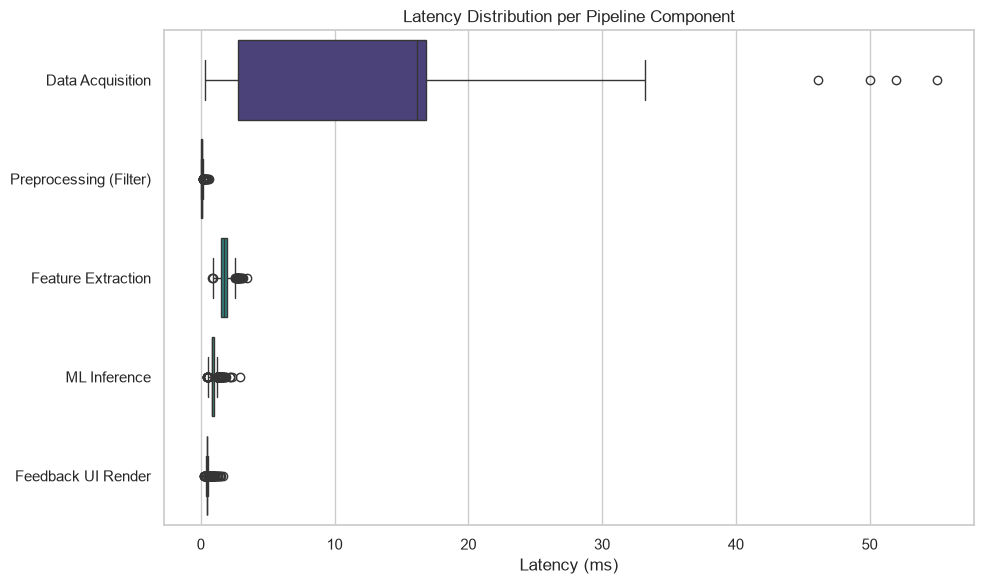

In [28]:

plt.figure(figsize=(10, 6))

# Capture the plot in the 'ax' variable
ax = sns.boxplot(data=df[components[:-1]], orient="h", palette="viridis")

# Apply clean, descriptive labels corresponding to the exact order of components[:-1]
ax.set_yticklabels([
    "Data Acquisition", 
    "Preprocessing (Filter)", 
    "Feature Extraction", 
    "ML Inference", 
    "Feedback UI Render"
])

plt.title("Latency Distribution per Pipeline Component")
plt.xlabel("Latency (ms)")
plt.tight_layout()
plt.show()

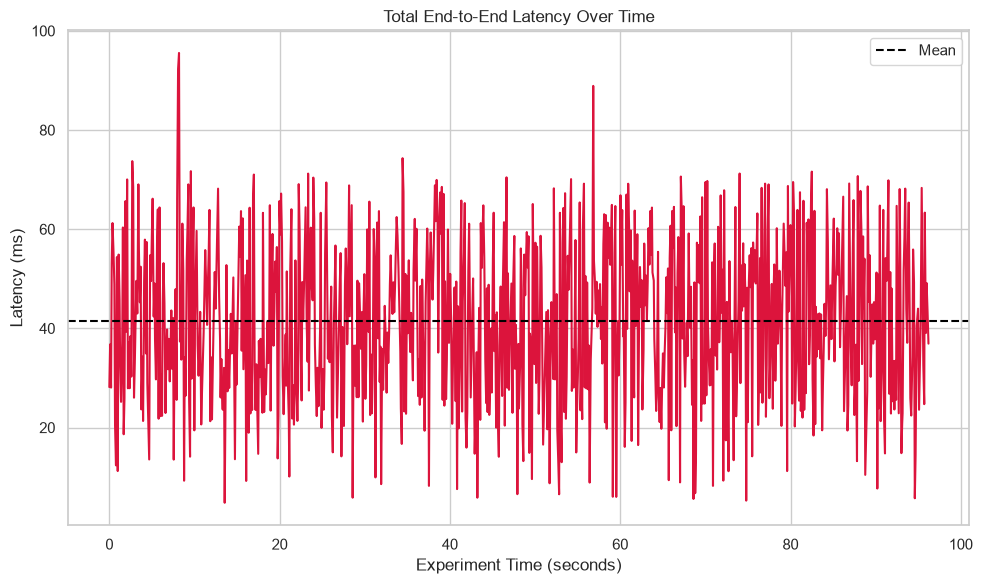

In [29]:
plt.figure(figsize=(10, 6))
sns.lineplot(x='Time_s', y='Total_End_to_End_ms', data=df, color="crimson", linewidth=1.5)
plt.title("Total End-to-End Latency Over Time")
plt.xlabel("Experiment Time (seconds)")
plt.ylabel("Latency (ms)")
plt.axhline(df['Total_End_to_End_ms'].mean(), color='black', linestyle='--', label="Mean")
plt.legend()
plt.tight_layout()
plt.show()

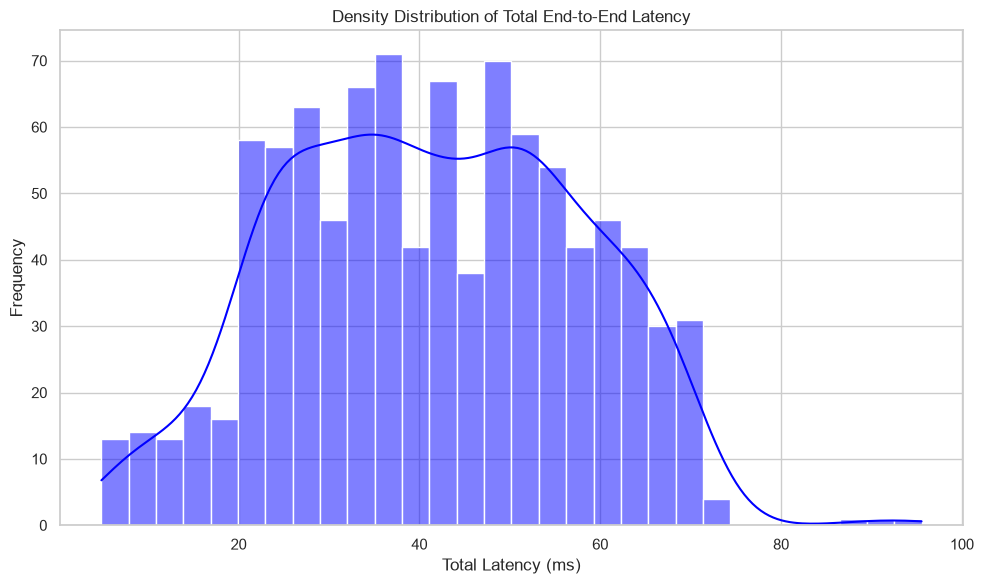

In [30]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Total_End_to_End_ms'], kde=True, color="blue", bins=30)
plt.title("Density Distribution of Total End-to-End Latency")
plt.xlabel("Total Latency (ms)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()